# Tiny Shakespeare with MND

Train a small character-level GPT for **2,000 steps** on
[Tiny Shakespeare](https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare).
Two transformer blocks, four attention heads, 64-dimensional embeddings.
Learning rate 0.003; no weight decay.

Install in the notebook's Python environment: `pip install mndopt matplotlib`.
Run all cells. CUDA is used when available; otherwise CPU.

In [1]:
from pathlib import Path
from shutil import which
from tempfile import gettempdir
from urllib.request import urlopen
import time

import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import torch
from torch import nn
from torch.nn import functional as F
from mndopt import MND

torch.manual_seed(42)
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 16
context_length = 64
width = 64
heads = 4
layers = 2
steps = 2_000
lr = 0.003
print(f"Device: {device}")

Device: cuda


## Data

Predict the next character. Use the first 90% for training and the rest for validation.
The download is cached in the system's temporary directory.

In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
path = Path(gettempdir()) / "mndopt-tiny-shakespeare.txt"
if not path.exists():
    with urlopen(url, timeout=30) as response:
        path.write_bytes(response.read())
text = path.read_text(encoding="utf-8")

characters = sorted(set(text))
vocab_size = len(characters)
stoi = {char: i for i, char in enumerate(characters)}

def encode(text):
    return [stoi[char] for char in text]

def decode(tokens):
    return "".join(characters[i] for i in tokens)

data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]

def get_batch(data, starts):
    x = torch.stack([data[i : i + context_length] for i in starts])
    y = torch.stack([data[i + 1 : i + context_length + 1] for i in starts])
    return x.to(device), y.to(device)

print(f"{len(text):,} characters; vocabulary: {vocab_size}")


train_starts = torch.randint(
    len(train_data) - context_length, (steps, batch_size),
    generator=torch.Generator().manual_seed(123),
)
eval_generator = torch.Generator().manual_seed(456)
eval_starts = {
    name: torch.randint(
        len(data) - context_length, (16, batch_size), generator=eval_generator
    )
    for name, data in (("Train", train_data), ("Validation", val_data))
}

1,115,394 characters; vocabulary: 65


## Model

Causal attention and a four-times-wider MLP, each with pre-layer normalization and a residual connection.

In [3]:
class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(width)
        self.qkv = nn.Linear(width, 3 * width)
        self.proj = nn.Linear(width, width)
        self.ln2 = nn.LayerNorm(width)
        self.mlp = nn.Sequential(
            nn.Linear(width, 4 * width), nn.GELU(), nn.Linear(4 * width, width)
        )

    def forward(self, x):
        batch, length, _ = x.shape
        q, k, v = self.qkv(self.ln1(x)).chunk(3, dim=-1)
        q, k, v = [
            t.reshape(batch, length, heads, width // heads).transpose(1, 2)
            for t in (q, k, v)
        ]
        attention = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        attention = attention.transpose(1, 2).reshape(batch, length, width)
        x = x + self.proj(attention)
        return x + self.mlp(self.ln2(x))


class GPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, width)
        self.position_embedding = nn.Embedding(context_length, width)
        self.blocks = nn.Sequential(*[Block() for _ in range(layers)])
        self.norm = nn.LayerNorm(width)
        self.lm_head = nn.Linear(width, vocab_size, bias=False)

    def forward(self, tokens):
        positions = torch.arange(tokens.size(1), device=tokens.device)
        x = self.token_embedding(tokens) + self.position_embedding(positions)
        return self.lm_head(self.norm(self.blocks(x)))


def init_weights(module):
    if isinstance(module, (nn.Linear, nn.Embedding)):
        nn.init.normal_(module.weight, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)


model = GPT().to(device)
model.apply(init_weights)
parameter_count = sum(p.numel() for p in model.parameters())
print(f"Parameters: {parameter_count:,}")
print(f"Tokens per run: {steps * batch_size * context_length:,}")
print(f"Tokens / parameter: {steps * batch_size * context_length / parameter_count:.1f}")

Parameters: 112,512
Tokens per run: 2,048,000
Tokens / parameter: 18.2


## Train

MND updates the attention and MLP matrices. Its built-in AdamW fallback updates
embeddings, the output layer, and vectors. Parameters stay in float32.

In [4]:
matrix_params, other_params = [], []
for name, parameter in model.named_parameters():
    use_mnd = parameter.ndim == 2 and name.startswith("blocks.")
    (matrix_params if use_mnd else other_params).append(parameter)

optimizer = MND([
    {"params": matrix_params, "matrix": True},
    {"params": other_params, "matrix": False},
], lr=lr)


def batch_loss(data, starts):
    x, y = get_batch(data, starts)
    logits = model(x)
    return F.cross_entropy(logits.flatten(0, 1), y.flatten())


@torch.no_grad()
def evaluate():
    model.eval()
    losses = [
        sum(batch_loss(data, starts).item() for starts in eval_starts[name])
        / len(eval_starts[name])
        for name, data in (("Train", train_data), ("Validation", val_data))
    ]
    model.train()
    return losses


history = [(0, *evaluate())]
start = time.perf_counter()
for step, starts in enumerate(train_starts, start=1):
    optimizer.zero_grad(set_to_none=True)
    loss = batch_loss(train_data, starts)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    if step % 100 == 0:
        train_loss, val_loss = evaluate()
        history.append((step, train_loss, val_loss))
        print(f"{step:4d} | train {train_loss:.3f} | val {val_loss:.3f}")

print(f"Elapsed: {time.perf_counter() - start:.1f} s (including evaluation)")

 100 | train 2.545 | val 2.535
 200 | train 2.477 | val 2.479
 300 | train 2.434 | val 2.430
 400 | train 2.383 | val 2.393
 500 | train 2.303 | val 2.310
 600 | train 2.233 | val 2.261
 700 | train 2.187 | val 2.221
 800 | train 2.127 | val 2.180
 900 | train 2.069 | val 2.120
1000 | train 2.030 | val 2.108
1100 | train 2.002 | val 2.076
1200 | train 1.967 | val 2.076
1300 | train 1.939 | val 2.043
1400 | train 1.915 | val 2.033
1500 | train 1.901 | val 2.025
1600 | train 1.894 | val 2.017
1700 | train 1.861 | val 1.987
1800 | train 1.850 | val 1.989
1900 | train 1.846 | val 1.963
2000 | train 1.831 | val 1.966
Elapsed: 27.7 s (including evaluation)


## Loss

Vector display with a high-resolution PNG fallback. LaTeX is used when installed.

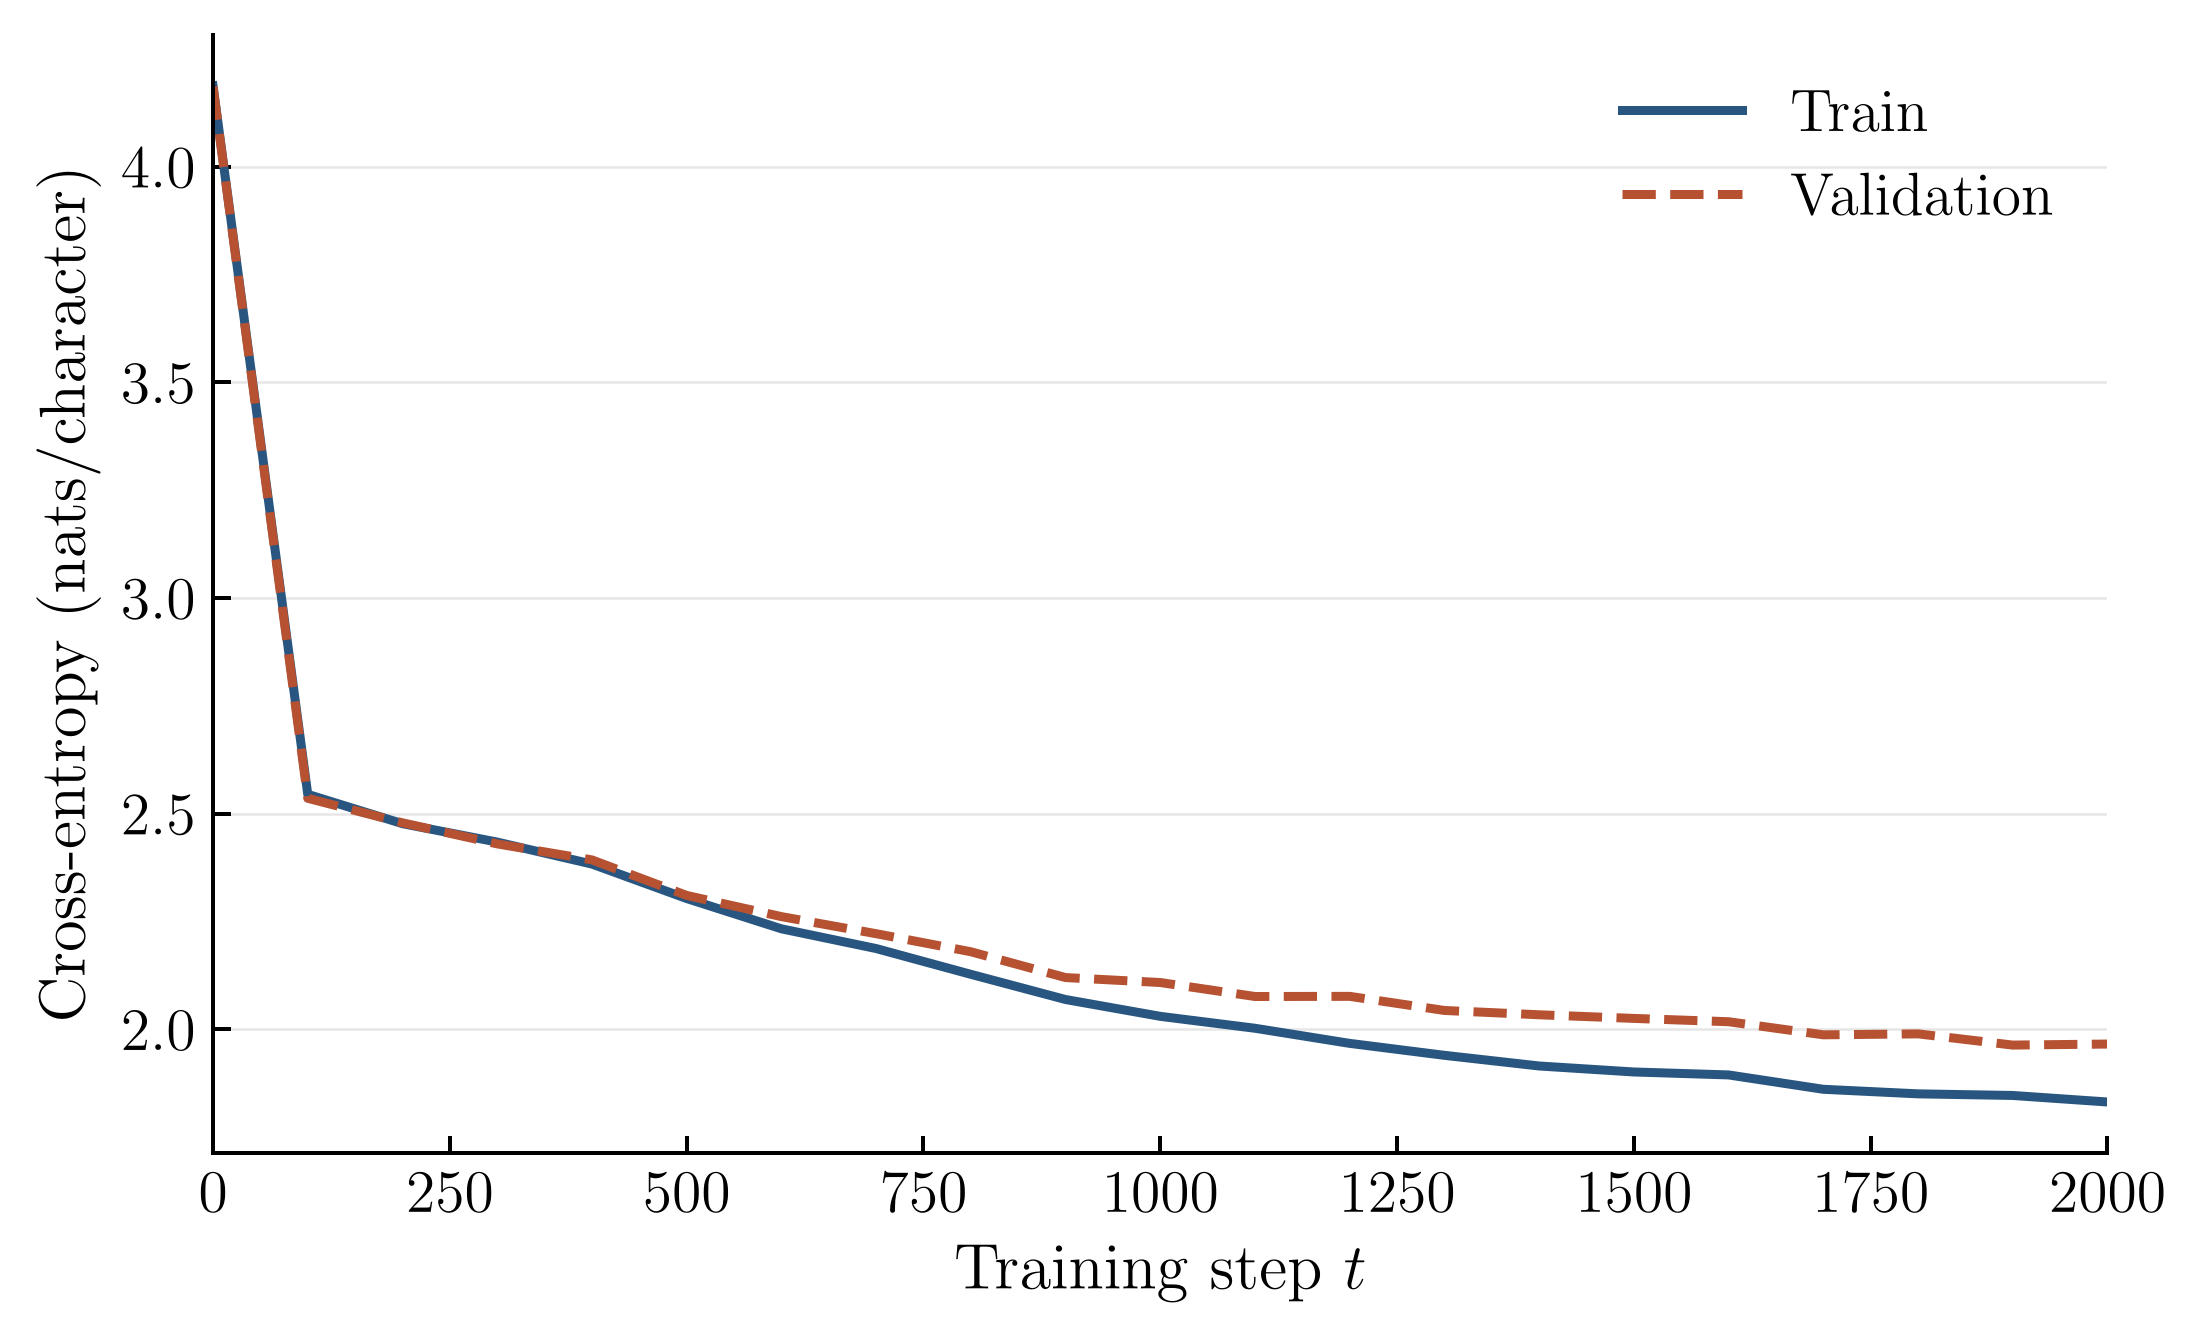

In [5]:
set_matplotlib_formats("svg", "retina")
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "text.usetex": bool(which("latex") and which("dvipng")),
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "figure.dpi": 180,
    "svg.fonttype": "path",
})

logged_steps, train_losses, val_losses = zip(*history)
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
ax.plot(logged_steps, train_losses, color="#285680", lw=1.8, label="Train")
ax.plot(logged_steps, val_losses, color="#b65132", lw=1.8, label="Validation", ls="--")
ax.set(xlabel=r"Training step $t$", ylabel="Cross-entropy (nats/character)",
       xlim=(0, steps))
ax.grid(axis="y", color="0.9", linewidth=0.5)
ax.legend(frameon=False)

plt.show()

## Sample

Generate 300 characters at temperature 0.8.

In [6]:
@torch.no_grad()
def generate(prompt="ROMEO:\n", new_tokens=300, temperature=0.8):
    model.eval()
    tokens = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    for _ in range(new_tokens):
        logits = model(tokens[:, -context_length:])[:, -1, :] / temperature
        next_token = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
        tokens = torch.cat((tokens, next_token), dim=1)
    return decode(tokens[0].tolist())


torch.manual_seed(789)
print(generate())

ROMEO:
The thoubble ave bee to ame, and the ther,
Which doughter a the with him a sposesell you the somiesh
I and your deten my fale will wore with
Forloow swither trees woul, with ladude
with with fould goood the somore.

KING LINGAREBRD IOLARD IURKES:
Faur genous dall I far to and our say.

So Parcial th
